# Imports and Reading data

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
plt.style.use('ggplot')
pd.set_option('display.max_columns', 200)

In [23]:
df_05up0001 = pd.read_csv('OTO-Plant_fix-0.5_0.001-100kshots.csv')
df_05down0001 = pd.read_csv('OTO-Plant_fix-0.5_-0.001-100kshots.csv')
df_055up0002 = pd.read_csv('OTO-Plant_fix-0.55_0.002-100kshots.csv')
df_045down0002 = pd.read_csv('OTO-Plant_fix-0.45_-0.002-100kshots.csv')
df_0525 = pd.read_csv('OTO-Plant_fix-0.525-100kshots.csv')
df_0475 = pd.read_csv('OTO-Plant_fix-0.475-100kshots.csv')

# Data understanding

In [24]:
print(df_05down0001.shape)
print(df_05up0001.shape)
print(df_055up0002.shape)
print(df_045down0002.shape)
print(df_0525.shape)
print(df_0475.shape)

# checking the sizes

(100000, 11)
(100000, 11)
(100000, 11)
(100000, 11)
(100000, 11)
(100000, 11)


In [25]:
df_05down0001.columns


Index(['optimizer_gain', 'dither_amplitude', 'dither_frequency', 'r_ideal_0',
       'lambda_r_ideal', 'energy_ESC', 'energy_const', 'energy_max',
       'choose_ESC', 'converged', 'convergence_time'],
      dtype='str')

In [26]:
df_05down0001.head(5)

# I forgot to remove the 2 columns 'r_ideal_0' and 'lambda_r_ideal' (they are constant), but it was only to make the tables look neat so it is fine

,optimizer_gain,dither_amplitude,dither_frequency,r_ideal_0,lambda_r_ideal,energy_ESC,energy_const,energy_max,choose_ESC,converged,convergence_time
0,0.001139,0.146914,3.125701,0.5,-0.001,3285.048311,3283.379213,3306.25,1,1,0.0
1,0.000347,0.590335,5.252188,0.5,-0.001,3283.641782,3283.379213,3306.25,1,1,0.0
2,0.015681,0.479735,9.883422,0.5,-0.001,3290.350238,3283.379213,3306.25,1,1,0.0
3,0.002587,0.764620,8.159639,0.5,-0.001,3284.379748,3283.379213,3306.25,1,1,0.0
4,0.003582,0.331008,9.513785,0.5,-0.001,3286.053951,3283.379213,3306.25,1,1,0.0


# Feature understanding

In [27]:
dfs = {
    '0.5 up 0.001': df_05up0001,
    '0.5 down 0.001': df_05down0001,
    '0.55 up 0.002': df_055up0002,
    '0.45 down 0.002': df_045down0002,
    '0.525': df_0525,
    '0.475': df_0475,
}

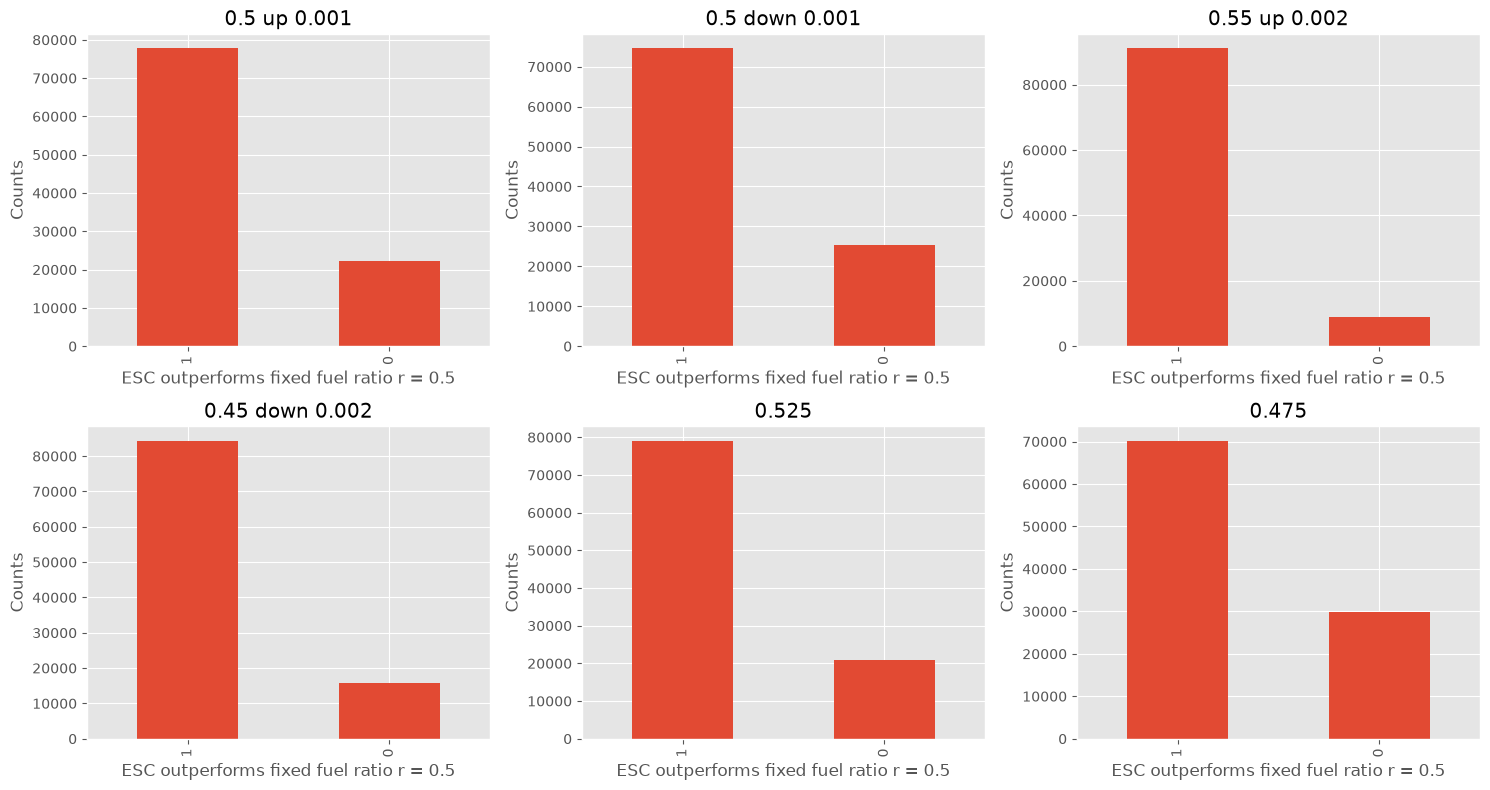

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, (name, df) in zip(axes.flat, dfs.items()):
    df['choose_ESC'].value_counts().plot(kind='bar', ax=ax, title=name)
    ax.set_xlabel('ESC outperforms fixed fuel ratio r = 0.5')
    ax.set_ylabel('Counts')

plt.tight_layout()
plt.show()

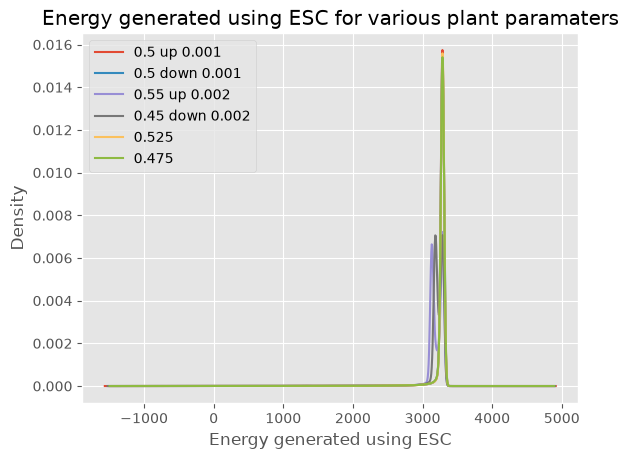

In [29]:
fig, ax = plt.subplots()

for name, df in dfs.items():
    df['energy_ESC'].plot(kind='kde', ax=ax, label=name)

ax.set_xlabel('Energy generated using ESC')
ax.set_ylabel('Density')
ax.set_title('Energy generated using ESC for various plant paramaters')
ax.legend()
plt.show()

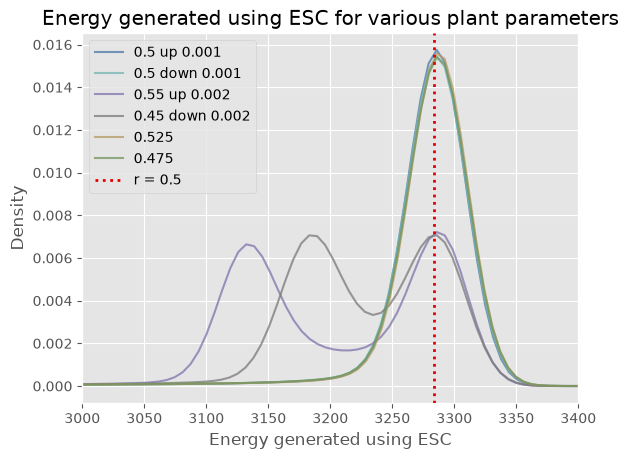

In [30]:
# rescaled with x = 3283.379213 as benchmark (energy generated using r = 0.5)

from itertools import cycle

fig, ax = plt.subplots()

colors = cycle([
    '#4C78A8', '#72B7B2', '#8073AC',
    '#797979', '#B59B64', '#73965C'
])

for name, df in dfs.items():
    df['energy_ESC'].plot(
        kind='kde', ax=ax, label=name,
        color=next(colors), alpha=0.75
    )

ax.axvline(
    x=3283.379213,
    color='#E60000',
    linestyle=':',
    linewidth=2,
    label='r = 0.5',
    zorder=10
)

ax.set_xlim(3000, 3400)
ax.set_xlabel('Energy generated using ESC')
ax.set_ylabel('Density')
ax.set_title('Energy generated using ESC for various plant parameters')
ax.legend()
plt.show()

# Feature relationship

## Energy vs. other features

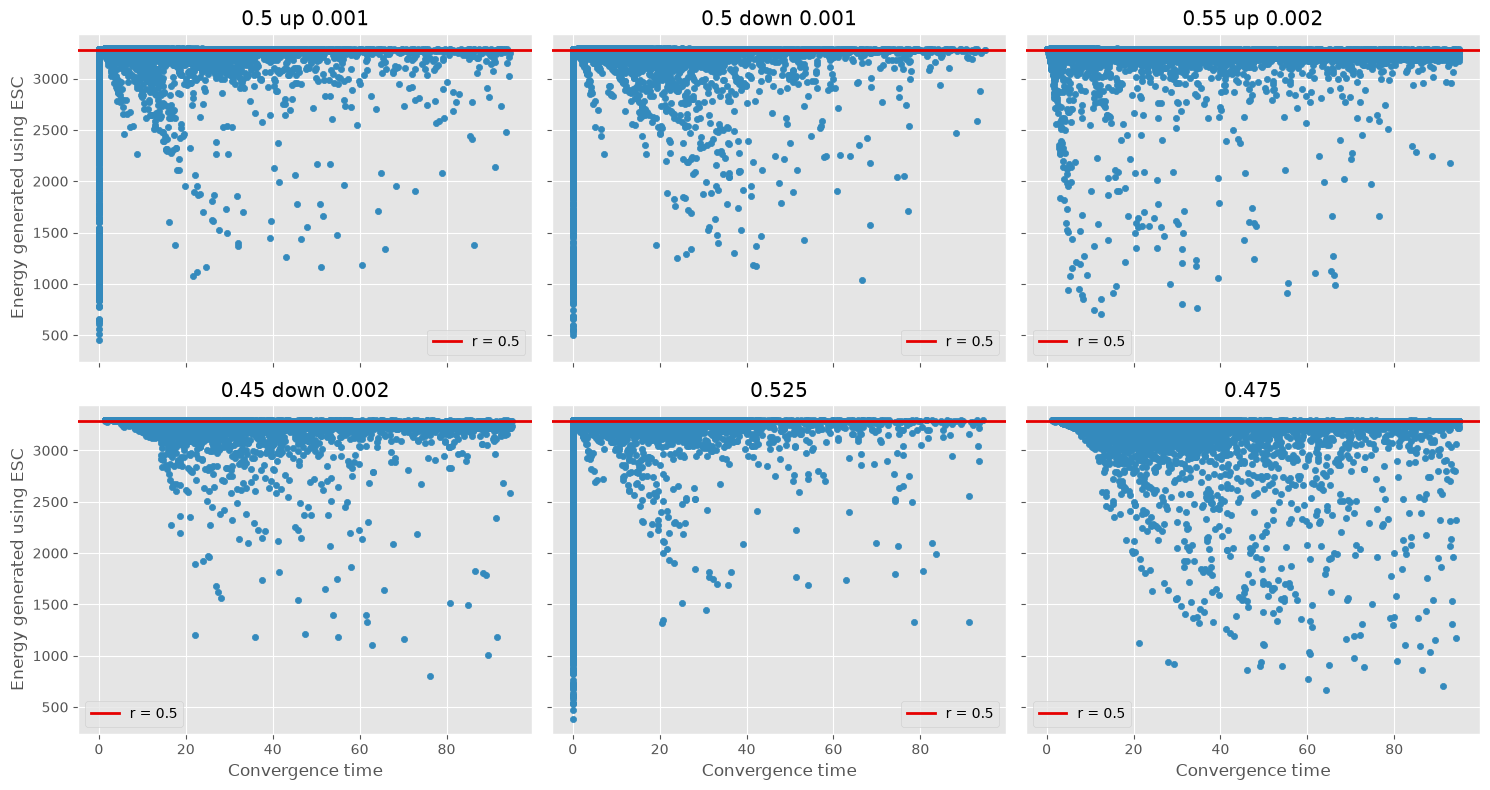

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)

for ax, (name, df) in zip(axes.flat, dfs.items()):
    df.plot(
        kind='scatter',
        x='convergence_time',
        y='energy_ESC',
        ax=ax,
        title=name
    )

    ax.axhline(
        y=3283.379213,
        color='#E60000',
        linestyle='-',
        linewidth=2,
        label='r = 0.5',
        zorder=10
    )

    ax.set_xlabel('Convergence time')
    ax.set_ylabel('Energy generated using ESC')
    ax.legend()

plt.tight_layout()
plt.show()

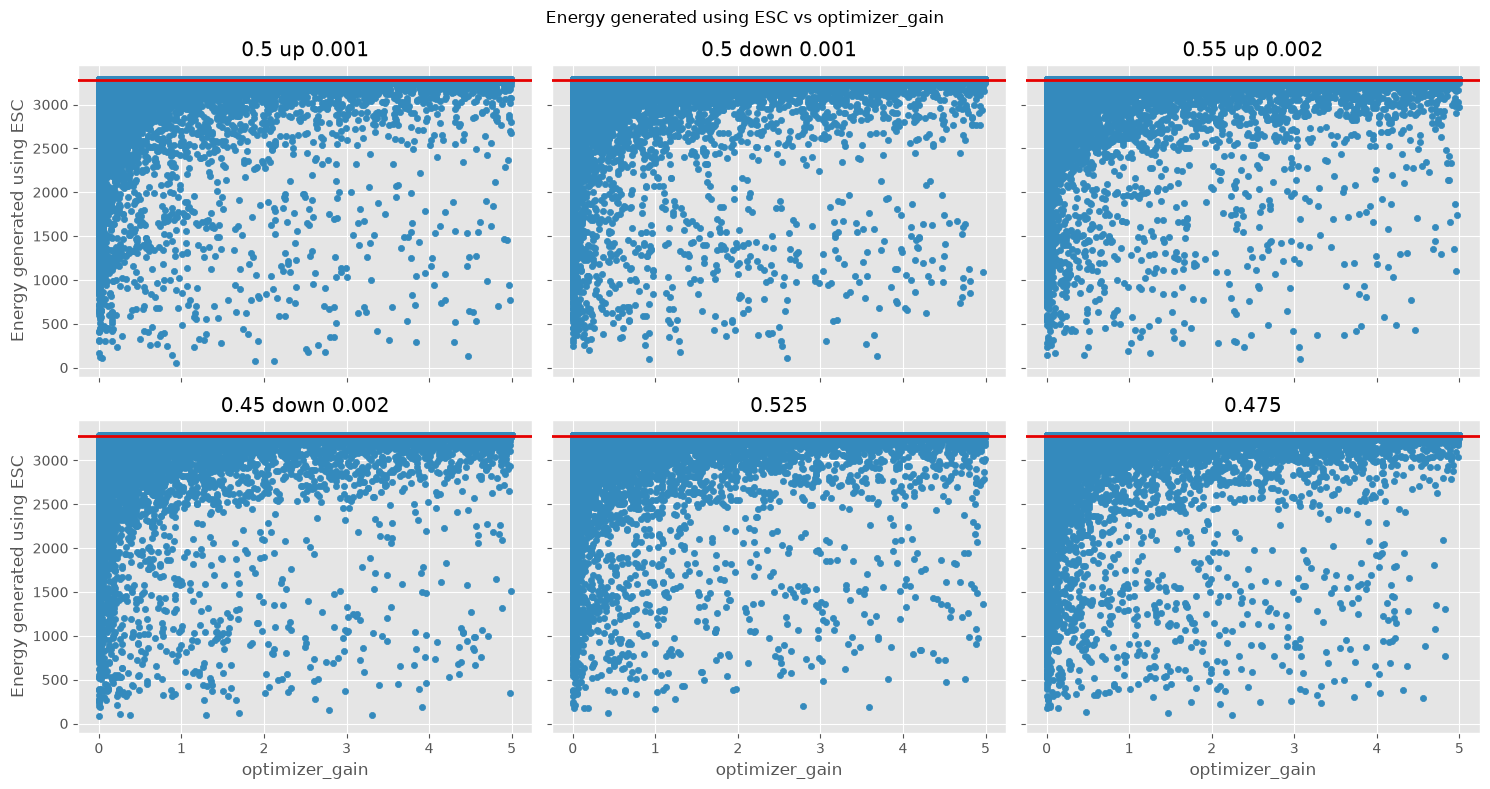

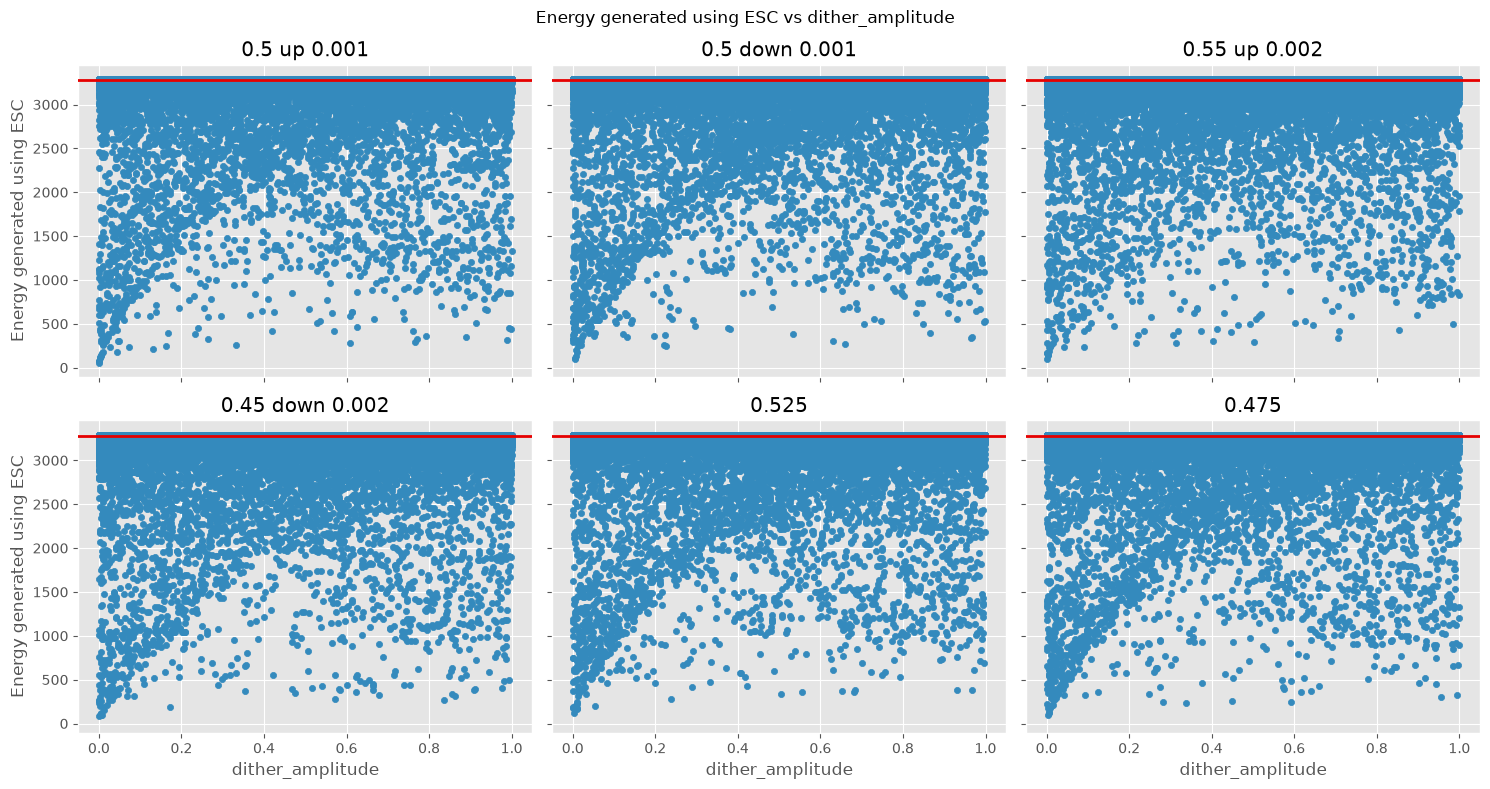

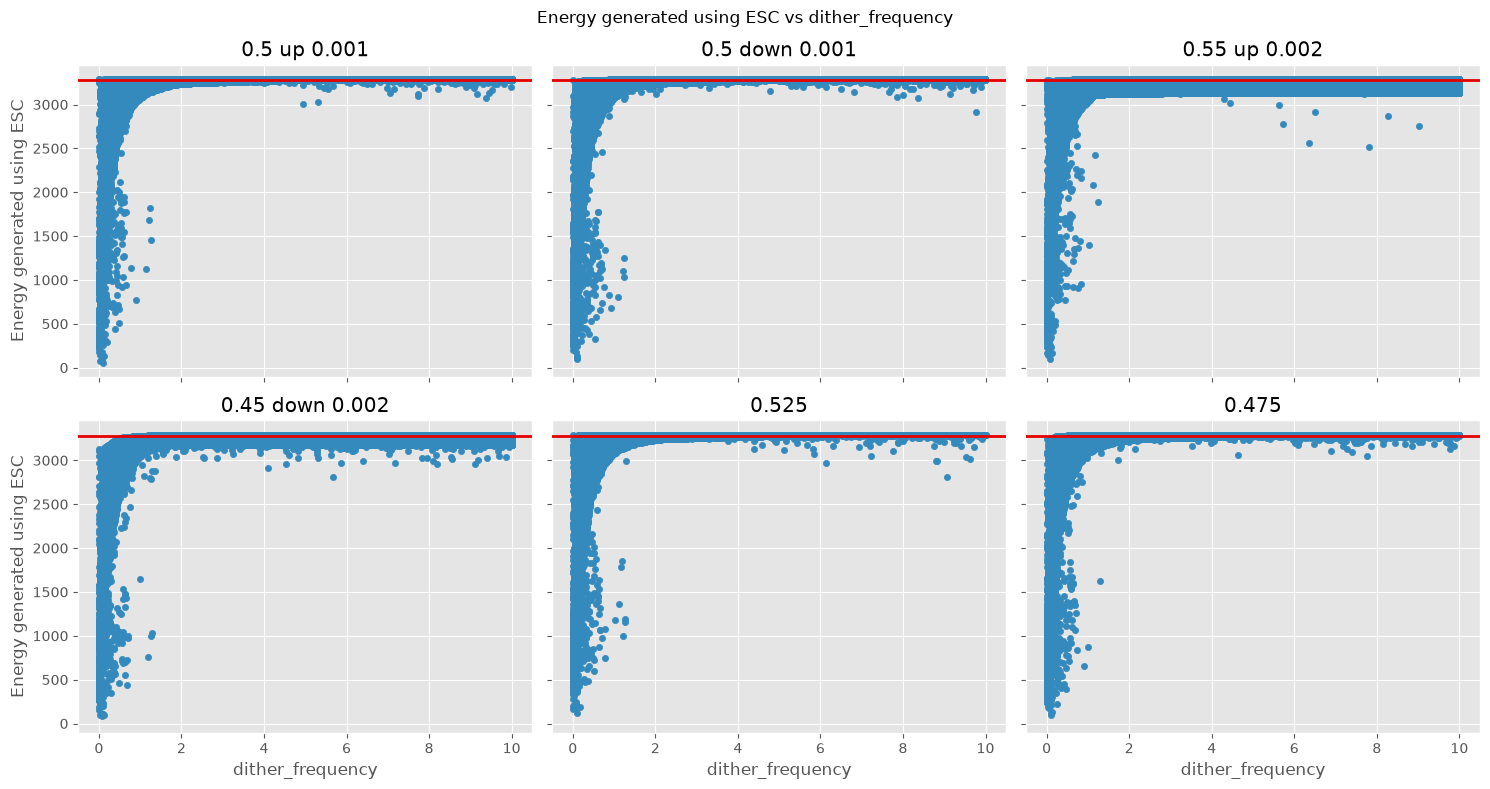

In [32]:
params = ['optimizer_gain', 'dither_amplitude', 'dither_frequency']

for p in params:
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)

    for ax, (name, df) in zip(axes.flat, dfs.items()):
        df.plot(kind='scatter',
                x=p,
                y='energy_ESC',
                ax=ax,
                title=name)

        ax.axhline(y=3283.379213,
                   color='#E60000',
                   linestyle='-',
                   linewidth=2,
                   label='r = 0.5',
                   zorder=10
        )
        ax.set_xlabel(p)
        ax.set_ylabel('Energy generated using ESC')

    fig.suptitle(f'Energy generated using ESC vs {p}')
    plt.tight_layout()
    plt.show()

## Symmetrical plant parameter analysis

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

In [34]:
# Setup

# Input columns the model uses, and the column it should predict
feature_cols = ['optimizer_gain', 'dither_amplitude', 'dither_frequency']
target = 'choose_ESC'

# Each pair is (dataset to train on, dataset to test on)
pairs = [
    ('0.5 up 0.001', '0.5 down 0.001'),
    ('0.55 up 0.002', '0.45 down 0.002'),
    ('0.525', '0.475'),
]

def to_tensors(df):
    # Pick the feature columns and turn them into a float32 tensor of shape (rows, features)
    X = torch.tensor(df[feature_cols].values, dtype=torch.float32)
    # Turn the labels into a float32 column of shape (rows, 1), which BCEWithLogitsLoss expects
    y = torch.tensor(df[target].values, dtype=torch.float32).reshape(-1, 1)
    return X, y

def make_model(n):
    # Build a new network with random weights; n = number of input features
    return nn.Sequential(
        nn.Linear(n, 32), nn.ReLU(),   # hidden layer 1: 32 neurons
        nn.Linear(32, 16), nn.ReLU(),  # hidden layer 2: 16 neurons
        nn.Linear(16, 1)               # output: 1 logit (no activation; the loss applies the sigmoid)
    )

def train(model, train_loader, Xtr, ytr, Xcv, ycv, epochs=300, lr=0.01):
    loss_fn = nn.BCEWithLogitsLoss()                         # binary cross-entropy that takes logits
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)  # updates the weights
    history = {'loss': [], 'val_loss': []}                   # loss per epoch, for the plot

    for epoch in range(epochs):
        # One pass over the training data, one mini-batch at a time
        for xb, yb in train_loader:
            optimizer.zero_grad()           # clear the gradients from the previous batch
            loss = loss_fn(model(xb), yb)   # forward pass and loss on this batch
            loss.backward()                 # backpropagation: compute gradients
            optimizer.step()                # adjust the weights using the gradients

        # After each epoch, record the loss on the full train and cv sets
        # (no_grad: no gradients needed, so this is faster)
        with torch.no_grad():
            history['loss'].append(loss_fn(model(Xtr), ytr).item())
            history['val_loss'].append(loss_fn(model(Xcv), ycv).item())

    return history

def predict_logits(model, X):
    # Run the model without tracking gradients and return the raw logits
    with torch.no_grad():
        return model(X)

def accuracy(model, X, y_true):
    # logits -> probabilities (sigmoid) -> 0/1 predictions (threshold 0.5) -> 1D array
    y_pred = (torch.sigmoid(predict_logits(model, X)).numpy() > 0.5).astype(int).flatten()
    # Return the accuracy and the predictions (needed for the confusion matrix)
    return accuracy_score(y_true, y_pred), y_pred

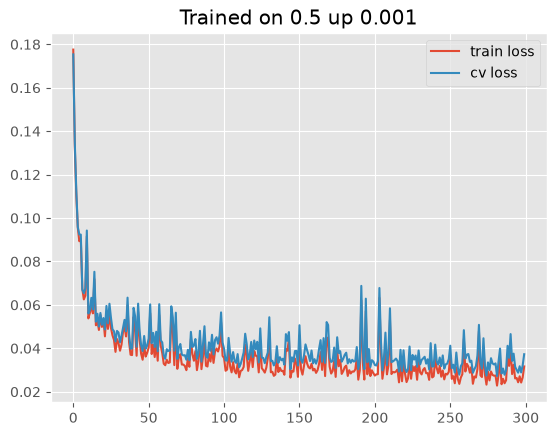

Trained on 0.5 up 0.001 -> tested on 0.5 down 0.001
Train accuracy: 0.988 | CV accuracy: 0.986 | Test accuracy: 0.962
[[21730  3690]
 [  130 74450]]
              precision    recall  f1-score   support

           0       0.99      0.85      0.92     25420
           1       0.95      1.00      0.97     74580

    accuracy                           0.96    100000
   macro avg       0.97      0.93      0.95    100000
weighted avg       0.96      0.96      0.96    100000



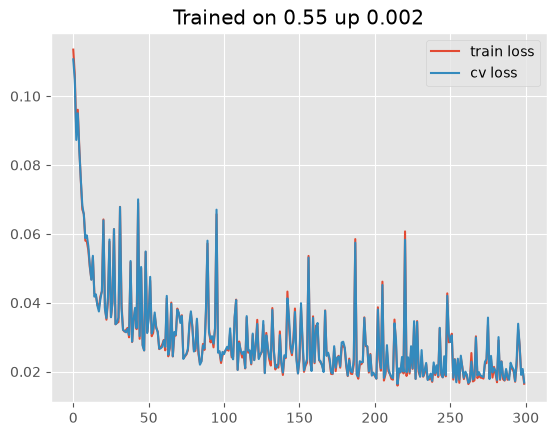

Trained on 0.55 up 0.002 -> tested on 0.45 down 0.002
Train accuracy: 0.995 | CV accuracy: 0.995 | Test accuracy: 0.930
[[ 8763  6930]
 [   43 84264]]
              precision    recall  f1-score   support

           0       1.00      0.56      0.72     15693
           1       0.92      1.00      0.96     84307

    accuracy                           0.93    100000
   macro avg       0.96      0.78      0.84    100000
weighted avg       0.94      0.93      0.92    100000



In [ ]:
# Train on one dataset of each pair, test on the other

results = {}  # stores the model and scores for each pair

for train_name, test_name in pairs:
    # Keep only the 3 parameters and the label; drop all other columns
    df_train = dfs[train_name][feature_cols + [target]]
    df_test = dfs[test_name][feature_cols + [target]]

    # Split the training dataset: 80% to train on, 20% for cross-validation
    tr, cv = train_test_split(df_train, test_size=0.20, random_state=1)

    # Convert to tensors (the _p names keep your earlier Xtr, Xcv etc. from being overwritten)
    Xtr_p, ytr_p = to_tensors(tr)
    Xcv_p, ycv_p = to_tensors(cv)
    Xte_p, _ = to_tensors(df_test)  # test labels stay as a pandas column for sklearn

    # Mini-batches of 100, reshuffled every epoch
    loader = DataLoader(TensorDataset(Xtr_p, ytr_p), batch_size=100, shuffle=True)

    # Same seed for every pair, so each model starts the same way and runs are reproducible
    torch.manual_seed(1)
    model = make_model(Xtr_p.shape[1])  # fresh model with 3 inputs, so pairs don't share weights

    # Train on the first dataset of the pair
    history = train(model, loader, Xtr_p, ytr_p, Xcv_p, ycv_p)

    # Plot train and cv loss over the epochs
    plt.plot(history['loss'], label='train loss')
    plt.plot(history['val_loss'], label='cv loss')
    plt.title(f'Trained on {train_name}')
    plt.legend()
    plt.show()

    # Accuracy on the training data, the cv data, and the other dataset (test)
    train_acc, _ = accuracy(model, Xtr_p, tr[target])
    cv_acc, _ = accuracy(model, Xcv_p, cv[target])
    test_acc, y_pred_test = accuracy(model, Xte_p, df_test[target])

    # Print the results for this pair
    print(f"Trained on {train_name} -> tested on {test_name}")
    print(f"Train accuracy: {train_acc:.3f} | CV accuracy: {cv_acc:.3f} | Test accuracy: {test_acc:.3f}")
    print(confusion_matrix(df_test[target], y_pred_test))       # rows = true class, columns = predicted
    print(classification_report(df_test[target], y_pred_test))  # precision, recall and f1 per class

    # Save everything so you can use it after the loop, e.g. results[('0.525', '0.475')]['model']
    results[(train_name, test_name)] = {'model': model, 'history': history,
                                        'train_acc': train_acc, 'cv_acc': cv_acc, 'test_acc': test_acc}

# Visualization

In [ ]:
import plotly.express as px

for name, d in dfs.items():
    # Text instead of numbers, so plotly uses two separate colours instead of a scale
    d_plot = d.assign(choose_ESC=d['choose_ESC'].astype(int).astype(str))

    fig = px.scatter_3d(d_plot,
                        x = 'optimizer_gain',
                        y = 'dither_amplitude',
                        z = 'dither_frequency',
                        color = 'choose_ESC',
                        color_discrete_map = {'0': '#3b4252', '1': '#3b7dd8'},
                        template = 'plotly_dark',
                        category_orders = {'choose_ESC': ['0', '1']},
                        title = f'3D scatter: choose ESC ({name})',
                        labels = {'optimizer_gain' : 'Optimizer gain',
                                  'dither_amplitude' : 'Dither amplitude',
                                  'dither_frequency' : 'Dither Frequency',
                                  'choose_ESC' : 'Choose ESC'})
    fig.update_traces(marker=dict(size=3))
    fig.show()

The symmetrical twins have high similarities in their shapes
The main difference comes from the dither frequency vs. dither amplitude side:
- The datasets with lower r_ideal tend to have higher "wave" than its symmtrical twin 
- Moreover, lower r_ideal sets have an "edge" at amplitude close to 0

This suggest the "wave" and "edge" form when r_ideal < 0.5

Further analysis suggestion: Start from r_ideal_0 > 0.5 and choose lambda_r_ideal so that it drifts to < 0.5.

After observing the 3D plot, I conclude that the most reasonable set of ESC parameters to try first is 1-0.2-6 because it converges fast and gets chosen over 0.5